# 01. FoldedVision AI — Lens CNN Baseline

**주제:** CNN 기반 정밀 광학 렌즈의 외관 결함 검출 및 사전 품질검사 효과 분석 (공개 데이터 PoC)

이 노트북은 Lens 데이터를 직접 확인하고, 지시서 구조 그대로의 **기본 CNN(Baseline)** 을 학습·평가해 기준 성능을 확보합니다. 자화전자의 실제 생산 데이터가 아니라 공개 데이터셋(VISION Datasets의 Lens)을 쓰는 기술 검증입니다.

### 먼저 알아야 할 데이터 사실
| 확인 항목 | 결과 |
|---|---|
| 정답 있는 사진 | train 66장 · val 63장 — **전부 결함 사진** |
| 공식 정상 사진 | **0장** |
| 정답 없는 사진 | inference 93장. 공식 문서상 비공개 테스트 사진과 '결함 주석이 없는 사진'이 섞여 있지만, 어느 것이 정상인지 정답이 없습니다. |

그래서 **사진 단위** 정상/불량 정답은 공식적으로 없습니다. 이 노트북은 대신 **구역(256×256) 단위 정상/불량 정답**을 실제 결함 마스크로 만들어 이진 CNN을 학습합니다. 구역 점수의 최댓값으로 사진 판정을 합칩니다. 정답 없는 사진을 정상으로 붙이거나 가짜 정상 사진을 만들지 않습니다.

### 읽는 순서 (지시서 PART 순서)
1. PART 01 환경 확인
2. 데이터 준비·검사
3. PART 02 EDA
4. 분할
5. PART 03 전처리(배율·구역)
6. PART 04 CNN 구조
7. PART 05 학습
8. PART 06 평가
9. PART 07 저장·장단점

`[TF]`로 시작하는 셀은 TensorFlow가 필요합니다. **처음에는 `RUN_MODE = "quick"`으로 끝까지 돌려 오류가 없는지 확인한 뒤 `"full"`로 실행하세요.**

In [22]:
# ── 실행 설정 (01 Baseline) ──
from pathlib import Path
import os
NOTEBOOK_ID = "01"
DATASET_NAME = "Lens"
RUN_MODE = "full"
assert RUN_MODE in ("quick", "full")
IMAGE_SIZE = 256  # 모델 입력 256×256×3
BATCH_SIZE = 16  # CPU에 맞춘 묶음 크기
SEED = 42  # 분할·초기화 재현
LEARNING_RATE = 1e-3  # Adam 학습률
CNN_EPOCHS = 2 if RUN_MODE == "quick" else 20  # 최대 epoch (EarlyStopping으로 더 일찍 끝날 수 있음)
CNN_PATIENCE = 5  # 검증 PR-AUC가 5 epoch 동안 좋아지지 않으면 멈춤
USE_SAVED_MODELS = True  # 데이터·설정이 완전히 같은 저장 모델만 재사용

### 경로와 공통 규칙
- `full` 결과는 `models/`, `outputs/`에 지시서의 이름 그대로 저장합니다.
- `quick` 결과는 `models/quick/`, `outputs/quick/`에 따로 저장합니다. 최종 결과를 덮어쓰지 않기 위해서입니다.

| 이름 | 값 | 의미 |
|---|---|---|
| `IMAGE_SIZE` | 256 | 모델 입력 = 256×256 RGB **구역(patch)** |
| `LENS_TARGET_DEFECT_PX` | 20 | 줄인 사진에서 결함 한 변이 약 20픽셀이 되도록 사진 크기 묶음별 배율을 정합니다. 사진 전체를 256으로 줄이면 작은 결함이 사라지기 때문입니다. |
| `STRIDE` | 192 | 구역을 3/4씩 옮깁니다. 겹치게 해서 경계에 걸친 결함을 놓치지 않습니다. |
| `VALID_MIN` | 0.2 | 렌즈 면(밝은 영역)이 20% 미만인 구역(거의 검은 배경)은 검사하지 않습니다. |
| `MIN_DEFECT_PX` | 4 | 구역 안 결함 픽셀이 4개 이상이면 불량 구역, 0개면 정상 구역, 1~3개(가장자리에 살짝 걸침)는 애매해서 학습·평가에서 뺍니다. |

In [23]:
# ── 공통 경로·규칙 (두 노트북 동일) ──
ROOT = Path.cwd().resolve()  # FoldedVision_Lens 폴더에서 실행하세요.
QUICK = RUN_MODE == "quick"
MODEL_DIR = ROOT / ("models/quick" if QUICK else "models")
OUT_DIR = ROOT / ("outputs/quick" if QUICK else "outputs")
FIG_DIR, PRED_DIR, MET_DIR, INTEG_DIR = OUT_DIR / "figures", OUT_DIR / "predictions", OUT_DIR / "metrics", OUT_DIR / "integration"
PROCESSED = ROOT / "data/processed"
for folder in [ROOT / "data/archives", ROOT / "data/raw", PROCESSED, MODEL_DIR, FIG_DIR, PRED_DIR, MET_DIR, INTEG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)  # 기존 파일은 지우지 않습니다.

LENS_TARGET_DEFECT_PX = 20
PATCH = IMAGE_SIZE  # 모델 입력 구역 한 변
STRIDE = PATCH * 3 // 4
VALID_MIN = 0.2
MIN_DEFECT_PX = 4
NEG_PER_POS = 2.0  # 학습 때 정상 구역을 불량 구역의 2배만 뽑습니다(전부 쓰면 정상이 너무 많음).
INTERNAL_VAL_FRACTION = 0.2  # 공식 train 안에서 내부 검증으로 떼는 비율(렌즈 묶음 단위)
RECALL_TARGET = 0.95  # NG 경계: 검증에서 불량 구역 Recall 95% 이상
REVIEW_RECALL = 0.99  # OK 경계: 검증에서 불량 구역 Recall 99% 이상(더 보수적) → 사이 구간이 REVIEW
QUICK_LIMIT = {"train": 8, "validation": 4, "test": 6}  # quick 모드에서 쓰는 사진 수
print("실행 모드:", RUN_MODE, "/ 모델 폴더:", MODEL_DIR, "/ 결과 폴더:", OUT_DIR)

실행 모드: full / 모델 폴더: C:\Project\Ai_Source\FoldedVision_Lens\models / 결과 폴더: C:\Project\Ai_Source\FoldedVision_Lens\outputs


## PART 01. 환경 확인
Python·TensorFlow·OpenCV 버전, CPU/GPU, 주요 라이브러리 설치 상태를 기록하고 랜덤 시드를 고정합니다. 기록은 `outputs/metrics/environment_01.json`에 저장합니다.

In [24]:
# 공통 도구: 파일 지문·한글 경로 이미지 읽기·JSON 저장 (TensorFlow 불필요)
import sys, json, tarfile, shutil, hashlib, time, platform
from collections import Counter, defaultdict
from datetime import datetime, timezone, timedelta
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("GRADIO_ANALYTICS_ENABLED", "False")
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
KST = timezone(timedelta(hours=9))
plt.rcParams["font.family"] = "Malgun Gothic" if platform.system() == "Windows" else "DejaVu Sans"  # 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False

def save_json(path, value):
    # 한글·들여쓰기 유지. NumPy 숫자도 일반 숫자로 바꿔 저장합니다.
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")

def sha256_file(path):
    # 파일 내용 지문: 같은 파일인지, 모델이 바뀌었는지 확인합니다.
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def read_rgb(path):
    # OpenCV는 BGR로 읽으므로 RGB로 바꿉니다. np.fromfile+imdecode는 한글 경로에서도 동작합니다.
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"이미지 읽기 실패(손상 가능): {path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def save_png(path, rgb_or_gray):
    # 한글 경로에도 저장되도록 imencode + tofile을 씁니다.
    array = cv2.cvtColor(rgb_or_gray, cv2.COLOR_RGB2BGR) if rgb_or_gray.ndim == 3 else rgb_or_gray
    cv2.imencode(".png", array)[1].tofile(str(path))

In [25]:
# [TF] TensorFlow를 불러오고 실행 환경을 기록합니다.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)  # Python·NumPy·TensorFlow 시드 고정
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
packages = {}
for name in ["gradio", "sklearn", "matplotlib"]:
    try:
        packages[name] = __import__(name).__version__
    except ImportError:
        packages[name] = "미설치"
environment = {"python": sys.version, "tensorflow": tf.__version__, "opencv": cv2.__version__, "numpy": np.__version__, "pandas": pd.__version__,
               "packages": packages, "gpu": [str(x) for x in tf.config.list_physical_devices("GPU")], "cpu": platform.processor(), "mode": RUN_MODE, "seed": SEED}
save_json(MET_DIR / f"environment_{NOTEBOOK_ID}.json", environment)
print(json.dumps(environment, ensure_ascii=False, indent=1))

{
 "python": "3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]",
 "tensorflow": "2.15.0",
 "opencv": "4.11.0",
 "numpy": "1.26.4",
 "pandas": "3.0.6",
 "packages": {
  "gradio": "6.32.0",
  "sklearn": "1.9.1",
  "matplotlib": "3.11.2"
 },
 "gpu": [],
 "cpu": "Intel64 Family 6 Model 197 Stepping 2, GenuineIntel",
 "mode": "full",
 "seed": 42
}


## 데이터 준비 — Lens.tar.gz 찾기와 안전한 압축 해제
1. **이미 풀린 폴더를 먼저 찾습니다.** `data` 아래에 Lens 폴더(`train/val/inference` + `_annotations.coco.json`)가 있으면 그대로 다시 씁니다. 압축을 다시 풀지 않습니다.
2. **없으면 압축파일을 찾습니다.** 찾는 순서는 현재 폴더 → `data/archives` → `data/raw` → `data` → Windows `다운로드` 폴더입니다. 이름은 `Lens.tar.gz`, `Lens_tar.gz` 둘 다 인식합니다. `data/archives` 밖에서 찾은 파일은 원본을 그대로 두고 **사본**을 `data/archives`에 둡니다.
3. **안전하게 풉니다.**
   - 압축 안 경로가 폴더 밖을 가리키거나(`..`, 절대경로) 링크·장치 파일이 있으면 멈춥니다.
   - 맥 메타데이터(`._*`)는 풀지 않습니다.
   - 임시 폴더에 다 푼 뒤에만 `data/raw/Lens_extracted`로 이름을 바꿉니다.
4. **어디에도 없으면** Hugging Face 공식 저장소에서 `Lens.tar.gz` 하나만 받습니다. 이 데이터셋은 이용 조건 동의가 필요한 '게이트' 데이터입니다. `huggingface-cli login`으로 로그인하고 웹에서 조건에 동의한 경우에만 받아집니다.

In [26]:
# Lens 데이터 폴더 찾기 → 없으면 압축 해제 → 그래도 없으면 공식 저장소에서 받기
HF_REPO, HF_FILE = "VISION-Workshop/VISION-Datasets", "Lens.tar.gz"

def find_lens_dataset_dirs(base):
    found = set()
    for annotation in Path(base).rglob("_annotations.coco.json"):
        top = annotation.parent.parent
        if annotation.parent.name == "train" and (top / "val/_annotations.coco.json").exists() and not top.name.startswith("."):
            found.add(top.resolve())
    return sorted(found)

def find_archives():
    places = [ROOT, ROOT / "data/archives", ROOT / "data/raw", ROOT / "data", Path.home() / "Downloads"]
    by_hash = {}
    for place in places:
        if not place.is_dir():
            continue
        for path in place.glob("Lens*"):
            if path.is_file() and (path.name.endswith(".gz") or path.name.endswith(".tgz")):
                by_hash.setdefault(sha256_file(path), path.resolve())  # 같은 내용이면 한 번만
    return by_hash

def safe_extract_tar(archive, destination):
    destination = Path(destination).resolve()
    with tarfile.open(archive, "r:*") as pack:
        members = pack.getmembers()
        if len(members) > 20000 or sum(m.size for m in members) > 5 * 1024**3:
            raise ValueError("예상하지 못한 압축 항목 수 또는 크기")
        for member in members:  # 쓰기 전에 전부 검사
            name = member.name.replace(chr(92), "/")
            if Path(name).is_absolute() or ".." in Path(name).parts or ":" in name:
                raise ValueError(f"압축파일 경로 이탈: {member.name}")
            if member.issym() or member.islnk() or member.isdev():
                raise ValueError(f"링크·장치 파일은 허용하지 않습니다: {member.name}")
        written = 0
        for member in members:
            if not member.isfile() or Path(member.name).name.startswith("._"):
                continue
            target = (destination / member.name).resolve()
            if not target.is_relative_to(destination):
                raise ValueError("압축파일 경로 이탈")
            target.parent.mkdir(parents=True, exist_ok=True)
            with pack.extractfile(member) as source, target.open("wb") as stream:
                shutil.copyfileobj(source, stream, length=1024 * 1024)
            written += 1
    return written

def download_from_hf():
    try:
        from huggingface_hub import hf_hub_download
    except ImportError:
        raise FileNotFoundError("Lens.tar.gz가 없습니다. 공식 VISION-Datasets에서 Lens.tar.gz를 받아 data/archives에 넣거나, pip install huggingface_hub 후 로그인하세요.")
    try:
        return Path(hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", local_dir=ROOT / "data/archives"))
    except Exception as error:
        raise FileNotFoundError(f"공식 저장소 다운로드 실패({type(error).__name__}). 이용 조건 동의·로그인이 필요한 데이터셋입니다: {error}")

def prepare_lens():
    existing = find_lens_dataset_dirs(ROOT / "data")
    archives = find_archives()
    if len(archives) > 1:
        raise ValueError("내용이 다른 Lens 압축파일이 여러 개입니다: " + ", ".join(map(str, archives.values())))
    archive_info = None
    if archives:
        archive_hash, archive = next(iter(archives.items()))
        if archive.parent != (ROOT / "data/archives").resolve():
            kept = ROOT / "data/archives" / ("Lens.tar.gz" if archive.name.endswith(".gz") else archive.name)
            if not kept.exists():
                shutil.copy2(archive, kept)  # 원본은 두고 사본을 프로젝트에 보관
            archive = kept
        archive_info = {"path": str(archive.relative_to(ROOT)), "bytes": archive.stat().st_size, "sha256": archive_hash}
    if len(existing) == 1:
        return existing[0], {"how": "이미 풀린 폴더 재사용", "archive": archive_info}
    if len(existing) > 1:
        raise ValueError("Lens 폴더가 여러 곳에 있습니다:\n" + "\n".join(map(str, existing)))
    if archive_info is None:
        archive = download_from_hf()
        archive_info = {"path": str(archive.relative_to(ROOT)), "bytes": archive.stat().st_size, "sha256": sha256_file(archive), "source": "huggingface"}
    extract_root = (ROOT / "data/raw/Lens_extracted").resolve()
    if extract_root.exists():
        raise ValueError(f"{extract_root} 가 있지만 Lens 구조가 아닙니다. 확인 후 이름을 바꿔 주세요(자동 삭제 안 함).")
    temporary = extract_root.with_name(".Lens_extracting")
    if temporary.exists():
        shutil.rmtree(temporary)  # 이전에 중단된 '임시' 해제본만 지웁니다.
    written = safe_extract_tar(ROOT / archive_info["path"], temporary)
    temporary.rename(extract_root)
    save_json(extract_root / ".complete.json", {**archive_info, "files_written": written, "extracted_at": datetime.now(KST).isoformat()})
    found = find_lens_dataset_dirs(extract_root)
    if len(found) != 1:
        raise ValueError("압축 안에서 Lens train/val 구조를 찾지 못했습니다.")
    return found[0], {"how": "지금 압축 해제", "files_written": written, "archive": archive_info}

LENS_DATA_DIR, LENS_SOURCE = prepare_lens()
save_json(MET_DIR / "lens_acquisition.json", {"dataset_dir": str(LENS_DATA_DIR), "official_source": HF_REPO + " / " + HF_FILE, **LENS_SOURCE})
print("Lens 데이터 폴더:", LENS_DATA_DIR, "/", LENS_SOURCE["how"])

Lens 데이터 폴더: C:\Project\Ai_Source\FoldedVision_Lens\data\Lens\Lens / 이미 풀린 폴더 재사용


## 데이터 구조 검사와 정상/불량 라벨 검증
COCO JSON의 `images`, `annotations`, `categories`를 직접 읽고 실제 사진 파일과 하나씩 대조합니다.
- 연결: JSON의 사진이 실제로 있는지, 반대로 JSON에 없는 사진은 없는지
- 손상·크기: 사진이 열리는지, JSON 크기와 실제 크기가 같은지
- bbox·polygon: 둘 다 있는지, polygon이 3점 이상이고 사진 범위 안인지, bbox와 범위가 맞는지
- 중복: 픽셀이 완전히 같은 사진이 있는지
- **정상/불량:** 정답이 있는 사진 중 결함 주석이 0개인 사진이 있는지(= 공식 정상 사진). 주석 없는 inference 사진을 정상으로 간주하지 않습니다.

In [27]:
# COCO 주석과 실제 사진을 하나씩 대조합니다.
LENS_SPLITS = ("train", "val", "inference")

def capture_group(width, height):
    # 사진 크기로 촬영 조건을 묶습니다. 학습에 없던 크기는 'other' = 적용 범위 밖입니다.
    if (width, height) == (512, 512):
        return "A_512_quadrant"
    if (width, height) == (2448, 2048):
        return "B_2448x2048"
    if min(width, height) >= 3000 and abs(width - height) <= 0.05 * max(width, height):
        return "C_3500_square"
    return "other"

def audit_lens():
    images, instances, errors, macos_meta, categories, coco_keys = [], [], [], [], {}, {}
    for split in LENS_SPLITS:
        folder = LENS_DATA_DIR / split
        coco = json.loads((folder / "_annotations.coco.json").read_text(encoding="utf-8"))
        coco_keys[split] = sorted(coco.keys())
        categories[split] = [(int(c["id"]), c["name"]) for c in coco["categories"]]
        disk = {p.name for p in folder.glob("*.jpg") if not p.name.startswith("._")}
        macos_meta += [f"{split}/{p.name}" for p in folder.glob("._*")]
        listed = [i["file_name"] for i in coco["images"]]
        errors += [{"split": split, "file": n, "reason": "JSON에 없는 사진"} for n in sorted(disk - set(listed))]
        errors += [{"split": split, "file": n, "reason": "사진 파일 없음"} for n in sorted(set(listed) - disk)]
        if len(listed) != len(set(listed)):
            errors.append({"split": split, "reason": "JSON 사진 이름 중복"})
        by_image = defaultdict(list)
        for annotation in coco["annotations"]:
            by_image[annotation["image_id"]].append(annotation)
        names = dict(categories[split])
        for info in coco["images"]:
            path = folder / info["file_name"]
            if not path.exists():
                continue
            try:
                rgb = read_rgb(path)
            except ValueError as error:
                errors.append({"split": split, "file": info["file_name"], "reason": str(error)})
                continue
            height, width = rgb.shape[:2]
            if (width, height) != (info["width"], info["height"]):
                errors.append({"split": split, "file": info["file_name"], "reason": "JSON 크기와 실제 크기 불일치"})
            key = f"{split}/{info['file_name']}"
            annotations = by_image.get(info["id"], [])
            images.append({"image_key": key, "image_id": key.replace("/", "_").replace(".jpg", ""), "official_split": split, "file": info["file_name"],
                           "path": str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path), "width": width, "height": height,
                           "capture_group": capture_group(width, height), "labeled": split != "inference", "n_instances": len(annotations),
                           "pixel_hash": hashlib.sha256(str(rgb.shape).encode() + rgb.tobytes()).hexdigest(),
                           "gray_like": bool(max(np.abs(rgb[..., 0].astype(int) - rgb[..., 1]).max(), np.abs(rgb[..., 1].astype(int) - rgb[..., 2]).max()) <= 8)})
            for annotation in annotations:
                problems = []
                polygons = annotation.get("segmentation") or []
                if isinstance(polygons, dict):
                    problems.append("RLE 형식(미지원)")
                    polygons = []
                points = [np.array(p, dtype=float).reshape(-1, 2) for p in polygons if len(p) >= 6]
                if not points:
                    problems.append("polygon 없음 또는 3점 미만")
                if any((p[:, 0] < -1).any() or (p[:, 0] > width + 1).any() or (p[:, 1] < -1).any() or (p[:, 1] > height + 1).any() for p in points):
                    problems.append("polygon이 사진 범위 밖")
                bbox = annotation.get("bbox")
                if not bbox:
                    problems.append("bbox 없음")
                    bbox = [0, 0, 0, 0]
                x, y, w, h = bbox
                if points:
                    allp = np.vstack(points)
                    if max(abs(allp[:, 0].min() - x), abs(allp[:, 1].min() - y), abs(allp[:, 0].max() - (x + w)), abs(allp[:, 1].max() - (y + h))) > 2:
                        problems.append("bbox와 polygon 범위 불일치")
                polygon_area = float(sum(abs(cv2.contourArea(p.astype(np.float32))) for p in points))
                instances.append({"image_key": key, "official_split": split, "annotation_id": annotation["id"], "category_id": int(annotation["category_id"]),
                                  "category": names.get(annotation["category_id"], "?"), "bbox_x": x, "bbox_y": y, "bbox_w": w, "bbox_h": h, "max_side": max(w, h),
                                  "center_x_norm": (x + w / 2) / width, "center_y_norm": (y + h / 2) / height, "coco_area": annotation.get("area"),
                                  "polygon_area": polygon_area, "polygon_fill_of_bbox": polygon_area / max(1.0, w * h), "n_polygons": len(points),
                                  "problems": ";".join(problems), "segmentation": json.dumps(polygons)})
                if problems:
                    errors.append({"split": split, "file": info["file_name"], "annotation_id": annotation["id"], "reason": ";".join(problems)})
    images, instances = pd.DataFrame(images), pd.DataFrame(instances)
    if len({tuple(v) for v in categories.values()}) != 1:
        errors.append({"reason": "폴더마다 결함 종류 목록이 다름"})
    labeled = images[images.labeled]
    duplicates = images[images.duplicated("pixel_hash", keep=False)]
    report = {
        "coco_top_level_keys": coco_keys, "categories": categories["train"],
        "total_images": int(len(images)), "images_per_split": images.groupby("official_split").size().to_dict(),
        "normal_images_official": int((labeled.n_instances == 0).sum()), "defect_images_official": int((labeled.n_instances > 0).sum()),
        "inference_images_without_label": int((images.official_split == "inference").sum()),
        "instances_per_split": instances.groupby("official_split").size().to_dict(),
        "instances_per_category": instances.category.value_counts().to_dict(),
        "images_containing_category": instances.groupby("category").image_key.nunique().to_dict(),
        "resolution_counts": (images.width.astype(str) + "x" + images.height.astype(str)).value_counts().to_dict(),
        "capture_groups": pd.crosstab(images.official_split, images.capture_group).to_dict(),
        "bbox_present": bool((instances.bbox_w > 0).all()), "polygon_present": bool((instances.n_polygons > 0).all()),
        "exact_duplicate_rows": int(len(duplicates)), "exact_duplicate_groups": [list(g.image_key) for _, g in duplicates.groupby("pixel_hash")],
        "gray_like_images": int(images.gray_like.sum()), "macos_metadata_files_skipped": len(macos_meta), "errors": errors,
        "binary_label_supported_at_image_level": bool((labeled.n_instances == 0).sum() > 0),
    }
    return images, instances, report

lens_images, lens_instances, lens_audit = audit_lens()
LENS_CATEGORIES = [name for _, name in sorted(lens_audit["categories"])]
print("전체 사진:", lens_audit["total_images"], "/ 공식 폴더별:", lens_audit["images_per_split"])
print("정답 있는 사진 중 정상:", lens_audit["normal_images_official"], "장 / 불량:", lens_audit["defect_images_official"], "장 / 정답 없는 inference:", lens_audit["inference_images_without_label"], "장")
print("결함 종류:", LENS_CATEGORIES)
print("결함 개수:", lens_audit["instances_per_category"])
print("bbox 있음:", lens_audit["bbox_present"], "/ polygon 있음:", lens_audit["polygon_present"], "/ 정확한 중복:", lens_audit["exact_duplicate_rows"], "/ 오류:", len(lens_audit["errors"]))
if lens_audit["errors"]:
    raise ValueError("연결·손상·형식 오류가 있습니다. 출력된 오류를 확인하세요.")
if not lens_audit["binary_label_supported_at_image_level"]:
    print("→ 공식 정상 사진이 없어 '사진 단위' 정상/불량 정답은 없습니다. 아래에서 '구역 단위' 정상/불량 정답을 실제 마스크로 만듭니다.")

전체 사진: 222 / 공식 폴더별: {'inference': 93, 'train': 66, 'val': 63}
정답 있는 사진 중 정상: 0 장 / 불량: 129 장 / 정답 없는 inference: 93 장
결함 종류: ['Fiber', 'Flash Particle', 'Hole', 'Surface Damage', 'Tear']
결함 개수: {'Fiber': 515, 'Surface Damage': 105, 'Tear': 35, 'Hole': 28, 'Flash Particle': 16}
bbox 있음: True / polygon 있음: True / 정확한 중복: 0 / 오류: 0
→ 공식 정상 사진이 없어 '사진 단위' 정상/불량 정답은 없습니다. 아래에서 '구역 단위' 정상/불량 정답을 실제 마스크로 만듭니다.


### 같은 렌즈의 조각 찾기 (누수 점검)
512×512 사진은 둥근 렌즈를 4등분한 조각입니다(한쪽 모서리가 검은 배경). 같은 렌즈의 이웃 조각이라면 **맞닿는 가장자리 픽셀**이 거의 같습니다. 가장자리 밝기 차이(평균 절댓값)를 비교해 다음 세 조건을 모두 만족하면 같은 렌즈로 묶습니다.
- 서로가 1등 짝일 것
- 차이가 1.6 이하일 것
- 2등 후보보다 1.3배 이상 확실할 것

이 묶음(`lens_group`)은 분할할 때 **같은 렌즈가 학습과 평가에 동시에 들어가지 않게** 하는 데 씁니다. 이 묶음은 추정이며, 큰 사진끼리 같은 렌즈를 다시 찍었는지는 확인할 수 없습니다.

In [28]:
# 512×512 사분면 조각의 가장자리를 비교해 같은 렌즈 묶음(lens_group)을 만듭니다.
def dark_corner(gray):
    corners = {"TL": gray[:20, :20].mean(), "TR": gray[:20, -20:].mean(), "BL": gray[-20:, :20].mean(), "BR": gray[-20:, -20:].mean()}
    return min(corners, key=corners.get)  # 가장 어두운 모서리 = 렌즈 바깥 → 어느 사분면인지

def find_quadrant_links(frame, max_diff=1.6, min_ratio=1.3):
    rows = frame[frame.capture_group == "A_512_quadrant"]
    gray = {r.image_key: cv2.cvtColor(read_rgb(ROOT / r.path), cv2.COLOR_RGB2GRAY).astype(np.float32) for r in rows.itertuples()}
    quadrant = {k: dark_corner(g) for k, g in gray.items()}
    links = []
    for first, second, edge in [("TL", "TR", "h"), ("BL", "BR", "h"), ("TL", "BL", "v"), ("TR", "BR", "v")]:
        left, right = [k for k in gray if quadrant[k] == first], [k for k in gray if quadrant[k] == second]
        if not left or not right:
            continue
        diff = np.array([[np.abs(gray[a][:, -1] - gray[b][:, 0]).mean() if edge == "h" else np.abs(gray[a][-1, :] - gray[b][0, :]).mean() for b in right] for a in left])
        for i, a in enumerate(left):
            j = int(diff[i].argmin())
            best, runner = float(diff[i, j]), (float(np.sort(diff[i])[1]) if diff.shape[1] > 1 else np.inf)
            mutual = int(diff[:, j].argmin()) == i
            links.append({"first": a, "second": right[j], "pair": first + "-" + second, "edge_diff": round(best, 3), "second_best": round(runner, 3),
                          "accepted": bool(mutual and best <= max_diff and runner >= min_ratio * best)})
    return pd.DataFrame(links), quadrant

def union_groups(keys, pairs):
    parent = {k: k for k in keys}
    def root(k):
        while parent[k] != k:
            parent[k] = parent[parent[k]]
            k = parent[k]
        return k
    for a, b in pairs:
        parent[root(a)] = root(b)
    roots = {k: root(k) for k in keys}
    names = {r: f"L{i:03d}" for i, r in enumerate(sorted(set(roots.values())))}
    return {k: names[r] for k, r in roots.items()}

quad_links, quad_position = find_quadrant_links(lens_images)
pairs = [(r.first, r.second) for r in quad_links[quad_links.accepted].itertuples()] + [(g[0], o) for g in lens_audit["exact_duplicate_groups"] for o in g[1:]]
lens_images["quadrant"] = lens_images.image_key.map(quad_position).fillna("")
lens_images["lens_group"] = lens_images.image_key.map(union_groups(list(lens_images.image_key), pairs))
quad_links.to_csv(PROCESSED / "lens_quadrant_links.csv", index=False, encoding="utf-8-sig")
spans = lens_images.groupby("lens_group").official_split.agg(lambda s: set(s))
lens_audit.update({"quadrant_links_accepted": int(quad_links.accepted.sum()),
                   "groups_spanning_official_train_and_val": int(spans.map(lambda s: {"train", "val"} <= s).sum()),
                   "groups_spanning_labeled_and_inference": int(spans.map(lambda s: "inference" in s and bool(s & {"train", "val"})).sum())})
save_json(PROCESSED / "lens_audit.json", lens_audit)
lens_images.to_csv(PROCESSED / "lens_image_manifest.csv", index=False, encoding="utf-8-sig")
lens_instances.drop(columns=["segmentation"]).to_csv(PROCESSED / "lens_instances.csv", index=False, encoding="utf-8-sig")
print("같은 렌즈 연결:", lens_audit["quadrant_links_accepted"], "쌍 / 공식 train·val에 걸친 렌즈:", lens_audit["groups_spanning_official_train_and_val"],
      "/ 정답 사진·inference에 걸친 렌즈:", lens_audit["groups_spanning_labeled_and_inference"])

같은 렌즈 연결: 43 쌍 / 공식 train·val에 걸친 렌즈: 8 / 정답 사진·inference에 걸친 렌즈: 12


## PART 02. EDA — 실제 데이터 분석
모든 그래프에 제목과 축 이름을 붙이고 `outputs/figures/`에 저장합니다.
1. 사진 개수와 분포 / 2. 정상·불량 비율 / 3. 결함 종류별 사진 수 / 4. 종류별 대표 사진 / 5. 해상도 / 6. 결함 위치 분포 / 7. 결함 크기 분포 / 8. 사진별 결함 개수

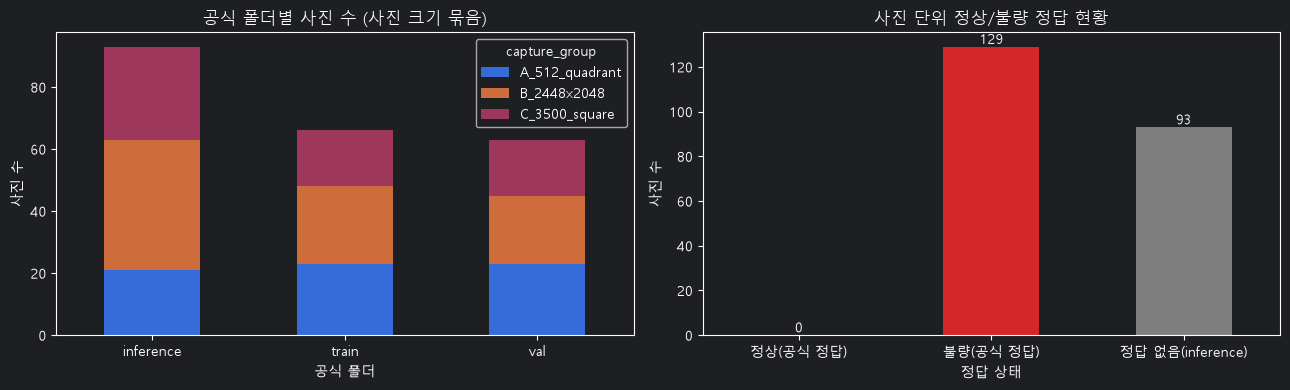

해상도(사진 크기 묶음별):
                 사진수  최소너비  최대너비  최소높이  최대높이
capture_group                              
A_512_quadrant   67   512   512   512   512
B_2448x2048      89  2448  2448  2048  2048
C_3500_square    66  3485  3640  3483  3651


In [29]:
# EDA 1·2·5: 사진 개수, 정상/불량 비율, 해상도
labeled = lens_images[lens_images.labeled]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.crosstab(lens_images.official_split, lens_images.capture_group).plot.bar(stacked=True, ax=axes[0])
axes[0].set(title="공식 폴더별 사진 수 (사진 크기 묶음)", xlabel="공식 폴더", ylabel="사진 수")
axes[0].tick_params(axis="x", rotation=0)
status = pd.Series({"정상(공식 정답)": lens_audit["normal_images_official"], "불량(공식 정답)": lens_audit["defect_images_official"], "정답 없음(inference)": lens_audit["inference_images_without_label"]})
status.plot.bar(ax=axes[1], color=["tab:green", "tab:red", "tab:gray"])
axes[1].set(title="사진 단위 정상/불량 정답 현황", xlabel="정답 상태", ylabel="사진 수")
axes[1].tick_params(axis="x", rotation=0)
for i, v in enumerate(status):
    axes[1].text(i, v, str(v), ha="center", va="bottom")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_image_counts.png", dpi=130)
plt.show()
sizes = lens_images.groupby("capture_group").agg(사진수=("image_key", "size"), 최소너비=("width", "min"), 최대너비=("width", "max"), 최소높이=("height", "min"), 최대높이=("height", "max"))
print("해상도(사진 크기 묶음별):\n", sizes)

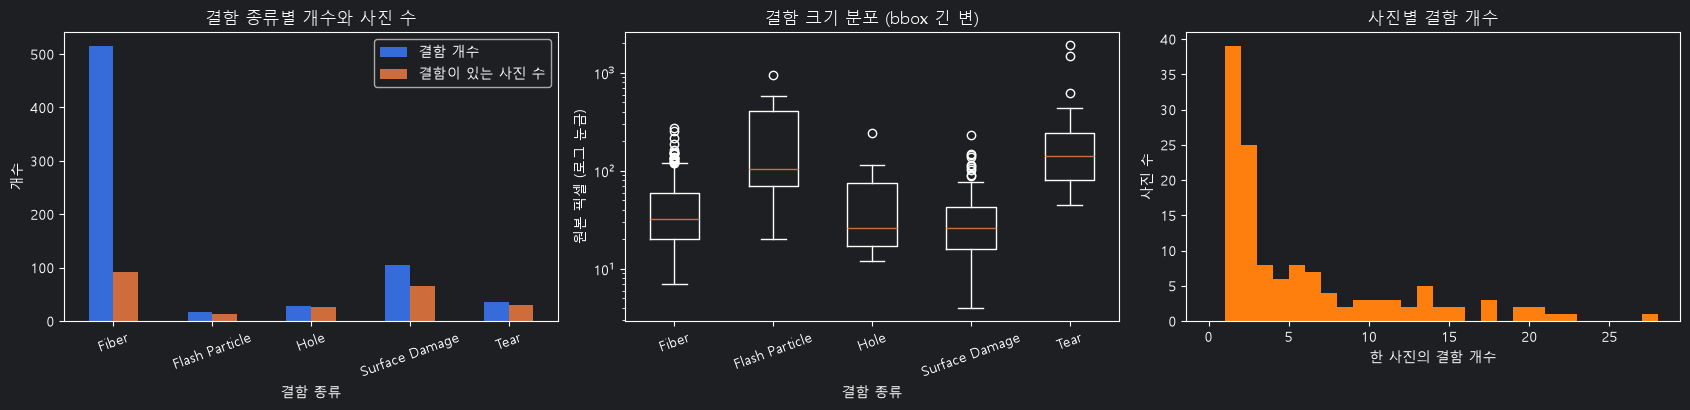

                결함 개수  결함이 있는 사진 수
category                          
Fiber             515           91
Flash Particle     16           13
Hole               28           27
Surface Damage    105           66
Tear               35           30
사진별 결함 개수: 중앙값 3.0 / 최대 27


In [30]:
# EDA 3·7·8: 결함 종류별 사진 수·개수, 크기 분포, 사진별 결함 개수
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
by_class = pd.DataFrame({"결함 개수": lens_instances.category.value_counts(), "결함이 있는 사진 수": lens_instances.groupby("category").image_key.nunique()})
by_class.plot.bar(ax=axes[0])
axes[0].set(title="결함 종류별 개수와 사진 수", xlabel="결함 종류", ylabel="개수")
axes[0].tick_params(axis="x", rotation=20)
order = by_class.index.tolist()
axes[1].boxplot([lens_instances.loc[lens_instances.category == c, "max_side"] for c in order])
axes[1].set_xticks(range(1, len(order) + 1), order)  # matplotlib 버전과 상관없이 이름 표시
axes[1].set_yscale("log")
axes[1].set(title="결함 크기 분포 (bbox 긴 변)", xlabel="결함 종류", ylabel="원본 픽셀 (로그 눈금)")
axes[1].tick_params(axis="x", rotation=20)
per_image = labeled.n_instances
axes[2].hist(per_image, bins=range(0, per_image.max() + 2), color="tab:orange")
axes[2].set(title="사진별 결함 개수", xlabel="한 사진의 결함 개수", ylabel="사진 수")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_class_size_count.png", dpi=130)
plt.show()
print(by_class)
print("사진별 결함 개수: 중앙값", per_image.median(), "/ 최대", per_image.max())

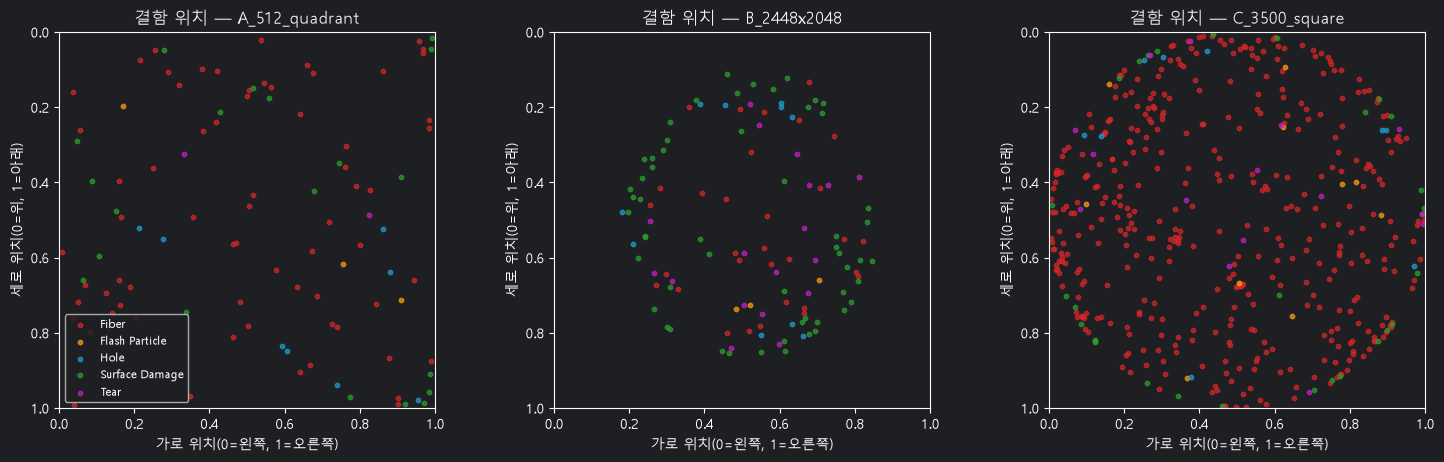

In [31]:
# EDA 6: 결함 위치 분포 (사진 안의 상대 위치 0~1, 사진 크기 묶음별)
groups = ["A_512_quadrant", "B_2448x2048", "C_3500_square"]
COLORS = ["#d62728", "#ff9f0e", "#1f9fd6", "#2ca02c", "#c41fc4"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, group in zip(axes, groups):
    part = lens_instances[lens_instances.capture_group == group] if "capture_group" in lens_instances else lens_instances[lens_instances.image_key.map(lens_images.set_index("image_key").capture_group) == group]
    for color, name in zip(COLORS, LENS_CATEGORIES):
        sub = part[part.category == name]
        ax.scatter(sub.center_x_norm, sub.center_y_norm, s=10, color=color, label=name, alpha=0.7)
    ax.set(title=f"결함 위치 — {group}", xlabel="가로 위치(0=왼쪽, 1=오른쪽)", ylabel="세로 위치(0=위, 1=아래)", xlim=(0, 1), ylim=(1, 0))
    ax.set_aspect("equal")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_defect_locations.png", dpi=130)
plt.show()

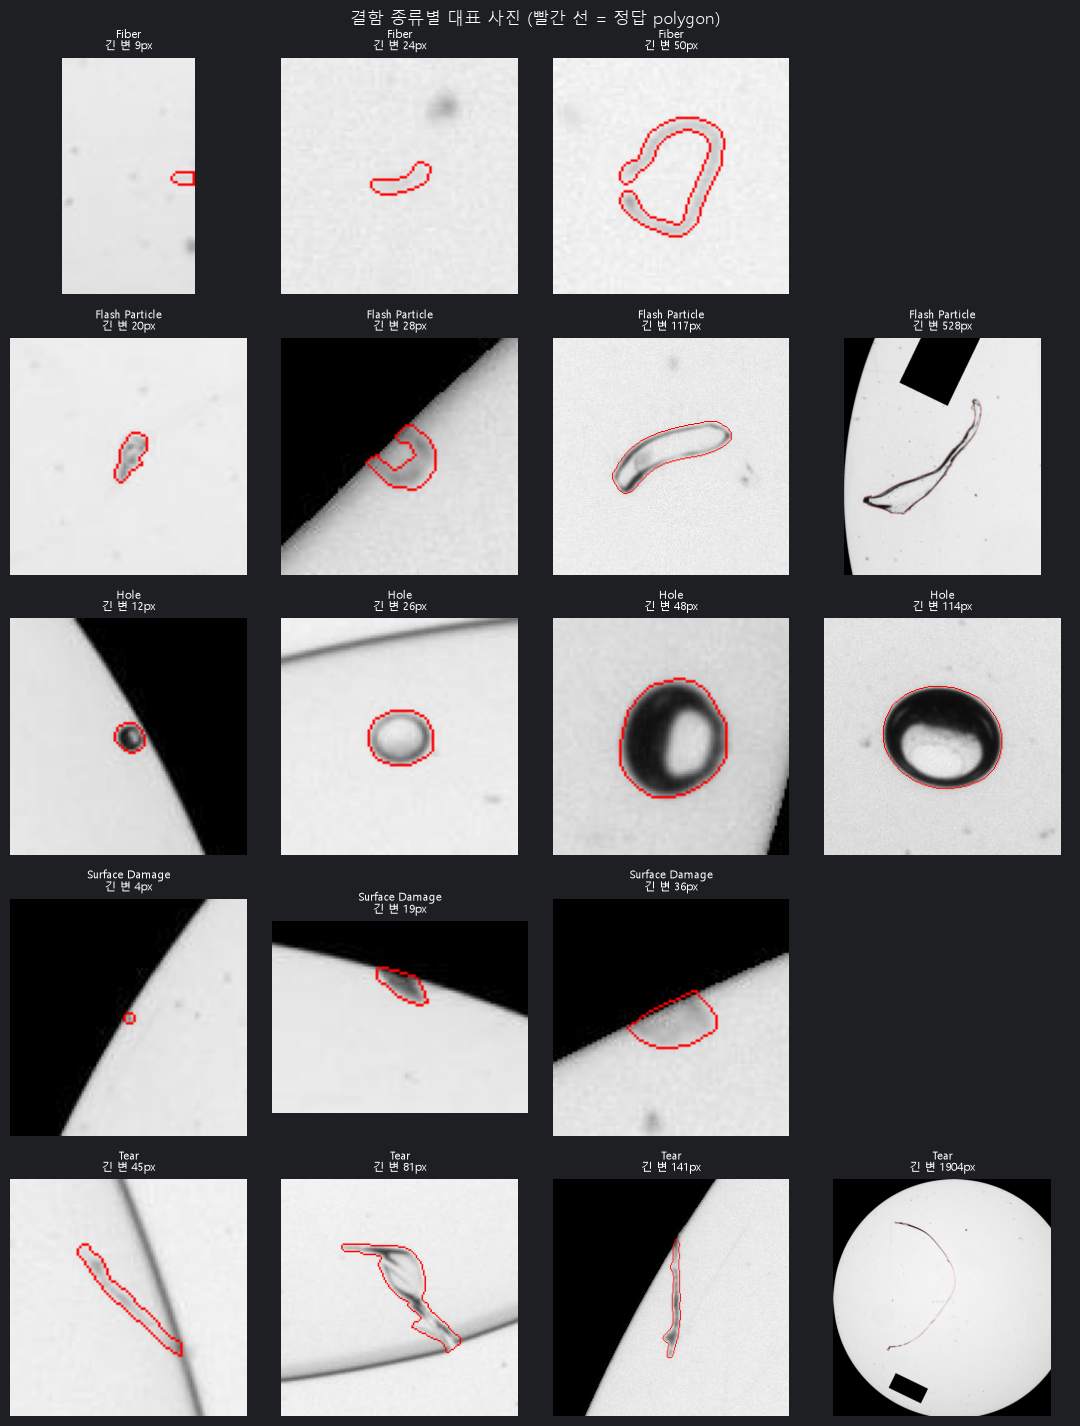

In [32]:
# EDA 4: 결함 종류별 대표 사진 (원본 + 정답 polygon, 결함 주변 확대)
fig, axes = plt.subplots(len(LENS_CATEGORIES), 4, figsize=(11, 2.9 * len(LENS_CATEGORIES)))
paths = lens_images.set_index("image_key").path
for row_axes, (cid, name) in zip(axes, enumerate(LENS_CATEGORIES)):
    samples = lens_instances[(lens_instances.category_id == cid) & (lens_instances.official_split == "train")].sort_values("max_side").iloc[::max(1, (lens_instances.category_id == cid).sum() // 6)].head(4)
    for ax in row_axes:
        ax.axis("off")
    for ax, inst in zip(row_axes, samples.itertuples()):
        rgb = read_rgb(ROOT / paths[inst.image_key])
        for poly in json.loads(inst.segmentation):
            cv2.polylines(rgb, [np.array(poly, np.int32).reshape(-1, 2)], True, (255, 0, 0), 1)
        half = int(max(48, inst.max_side))
        cx, cy = int(inst.bbox_x + inst.bbox_w / 2), int(inst.bbox_y + inst.bbox_h / 2)
        crop = rgb[max(0, cy - half):cy + half, max(0, cx - half):cx + half]
        ax.imshow(crop)
        ax.set_title(f"{name}\n긴 변 {inst.max_side:.0f}px", fontsize=8)
fig.suptitle("결함 종류별 대표 사진 (빨간 선 = 정답 polygon)")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_representative_defects.png", dpi=130)
plt.show()

## 학습·검증·최종 평가 분할
지시서 원칙대로 **공식 Train 안에서 내부 검증을 만들고, 공식 Val을 최종 평가(test)로 유지합니다.** 같은 렌즈 누수를 막기 위해 두 가지를 더 합니다.

1. **공식 Val → test:** 단, 공식 Train과 같은 렌즈로 판단된 Val 사진은 test에서 **뺍니다**(`excluded_same_lens_as_train`, 11장). 이 사진은 학습에도 넣지 않습니다.
2. **공식 Train → train / validation:** 렌즈 묶음 단위로 섞어서(시드 42) 촬영 크기 묶음마다 약 80% / 20%로 나눕니다.

- 모델·전처리·경계 선택에는 **validation만** 씁니다.
- test는 모든 선택이 끝난 뒤에 평가합니다.
- inference(정답 없음)는 정량 평가에 쓰지 않습니다.

In [33]:
# 공식 Val은 최종 평가로 유지하고, 공식 Train만 렌즈 묶음 단위로 train/validation으로 나눕니다.
rng = np.random.default_rng(SEED)
lens_images["split"] = "inference"
train_groups = set(lens_images.loc[lens_images.official_split == "train", "lens_group"])
is_val = lens_images.official_split == "val"
leaked = is_val & lens_images.lens_group.isin(train_groups)
lens_images.loc[is_val & ~leaked, "split"] = "test"
lens_images.loc[leaked, "split"] = "excluded_same_lens_as_train"
official_train = lens_images[lens_images.official_split == "train"]
for _, block in official_train.groupby("capture_group"):
    groups = sorted(block.lens_group.unique())
    rng.shuffle(groups)
    sizes, running = block.groupby("lens_group").size(), 0
    for group in groups:
        chosen = "validation" if running / len(block) < INTERNAL_VAL_FRACTION else "train"
        lens_images.loc[(lens_images.lens_group == group) & (lens_images.official_split == "train"), "split"] = chosen
        running += sizes[group]

used = lens_images[lens_images.split.isin(["train", "validation", "test"])]
for column in ["lens_group", "pixel_hash"]:
    assert (used.groupby(column).split.nunique() == 1).all(), f"{column} 기준 분할 누수"
image_split = lens_images.set_index("image_key").split
lens_instances["split"] = lens_instances.image_key.map(image_split)
lens_instances["capture_group"] = lens_instances.image_key.map(lens_images.set_index("image_key").capture_group)
SPLIT_SIGNATURE = hashlib.sha256(json.dumps(sorted(zip(lens_images.image_key, lens_images.split, lens_images.pixel_hash))).encode()).hexdigest()
lens_images.to_csv(PROCESSED / "lens_split_manifest.csv", index=False, encoding="utf-8-sig")
split_table = pd.crosstab(lens_images.split, lens_images.capture_group, margins=True)
print(split_table)
print(pd.crosstab(lens_instances.category, lens_instances.split))

def split_keys(split):
    keys = sorted(lens_images.loc[lens_images.split == split, "image_key"])
    return keys[: QUICK_LIMIT[split]] if QUICK and split in QUICK_LIMIT else keys

capture_group                A_512_quadrant  B_2448x2048  C_3500_square  All
split                                                                       
excluded_same_lens_as_train              11            0              0   11
inference                                21           42             30   93
test                                     12           22             18   52
train                                    16           20             14   50
validation                                7            5              4   16
All                                      67           89             66  222
split           excluded_same_lens_as_train  test  train  validation
category                                                            
Fiber                                    20   243    205          47
Flash Particle                            0     8      3           5
Hole                                      1    13     11           3
Surface Damage                         

## PART 03. 기본 전처리 (OpenCV)
| 단계 | 방법 | 이유 |
|---|---|---|
| RGB 변환 | `cv2.imdecode` → `COLOR_BGR2RGB` | OpenCV는 BGR로 읽습니다. 모델과 UI 모두 RGB로 통일합니다. |
| Resize | 사진 크기 묶음별 **작업 배율**(`INTER_AREA`) | 사진 전체를 256×256으로 줄이면 작은 결함이 1~3픽셀로 사라집니다(아래 셀에서 확인). |
| 256×256 입력 | 줄인 사진을 256×256 **구역**으로 자름 | 지시서의 기본 입력 크기를 지키면서 작은 결함을 보존합니다. |
| Normalize | 모델 첫 층 `Rescaling(1/255)` | 0~255 → 0~1. 모델 안에서 한 번만 하므로 UI·팀 통합에서 따로 나눌 필요가 없습니다. |
| Grayscale | 사용하지 않음 | 사진이 원래 흑백(R=G=B)입니다. 지시서 규격(RGB 3채널)을 그대로 지킵니다. |
| 증강 | `RandomFlip`(좌우·상하) | 학습할 때만 작동합니다. 둥근 렌즈라 뒤집어도 자연스럽습니다. |

## 작업 배율·정답 마스크·렌즈 영역
- **작업 배율:** *train 결함 크기만 보고* 사진 크기 묶음별로 정합니다. 계산식은 `20 ÷ (train 결함 bbox 긴 변의 중앙값)`이고, 0.25~1.0으로 제한합니다. 사진은 `INTER_AREA`로 줄입니다.
- **정답 마스크:** polygon 좌표에 배율을 곱한 뒤 그 크기에서 직접 그립니다(`cv2.fillPoly`). 큰 마스크를 줄이다가 작은 결함이 사라지는 일이 없습니다. 마스크를 resize해야 할 때는 최근접 보간만 씁니다.
- **렌즈 영역:** 밝은 렌즈 면(밝기 > 60)만 '검사 영역'으로 봅니다. 사진 픽셀만으로 계산하고 정답은 쓰지 않습니다. 검은 배경·고정틀·가림 사각형은 검사하지 않습니다.

In [34]:
# train 결함 크기로 배율을 정하고, 줄인 사진·마스크·렌즈 영역을 준비합니다.
train_sizes = lens_instances[lens_instances.split == "train"].groupby("capture_group").max_side.median()
LENS_SCALE = {g: float(np.clip(LENS_TARGET_DEFECT_PX / s, 0.25, 1.0)) for g, s in train_sizes.items() if g != "other"}
print("train 결함 긴 변 중앙값:", train_sizes.round(1).to_dict(), "→ 작업 배율:", {k: round(v, 3) for k, v in LENS_SCALE.items()})

def to_work(rgb, group):
    scale = LENS_SCALE[group]
    height, width = rgb.shape[:2]
    if scale == 1.0:
        return rgb.copy(), scale
    return cv2.resize(rgb, (max(1, round(width * scale)), max(1, round(height * scale))), interpolation=cv2.INTER_AREA), scale

def valid_region(rgb):
    # 밝은 렌즈 면만 True (사진 픽셀만 사용)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask = (cv2.GaussianBlur(gray, (5, 5), 0) > 60).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    keep = np.zeros(count, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= 0.05 * mask.size
    return keep[labels]

def rasterize(rows, shape, scale):
    mask = np.zeros(shape, np.uint8)
    instances = []
    for row in rows.itertuples():
        points = [np.round(np.array(p, np.float32).reshape(-1, 2) * scale).astype(np.int32) for p in json.loads(row.segmentation) if len(p) >= 6]
        if not points:
            continue
        cv2.fillPoly(mask, points, 1)
        allp = np.vstack(points)
        x0, y0 = max(0, int(allp[:, 0].min())), max(0, int(allp[:, 1].min()))
        local = np.zeros((int(allp[:, 1].max()) - y0 + 1, int(allp[:, 0].max()) - x0 + 1), np.uint8)
        cv2.fillPoly(local, [p - np.array([x0, y0], np.int32) for p in points], 1)
        local = local[: shape[0] - y0, : shape[1] - x0].astype(bool)
        instances.append({"category": row.category_id, "y0": y0, "x0": x0, "y1": y0 + local.shape[0], "x1": x0 + local.shape[1], "mask": local, "points": points})
    return mask, instances

lens_work = {}
vanished = 0
for split in ("train", "validation", "test"):
    for key in split_keys(split):
        row = lens_images.set_index("image_key").loc[key]
        image, scale = to_work(read_rgb(ROOT / row.path), row.capture_group)
        mask, instances = rasterize(lens_instances[lens_instances.image_key == key], image.shape[:2], scale)
        vanished += sum(int(not inst["mask"].any()) for inst in instances)
        lens_work[key] = {"image": image, "mask": mask, "instances": instances, "valid": valid_region(image), "split": split, "group": row.capture_group, "scale": scale}
print("준비한 사진:", len(lens_work), "/ 줄인 뒤 사라진 결함:", vanished)

train 결함 긴 변 중앙값: {'A_512_quadrant': 21.0, 'B_2448x2048': 25.0, 'C_3500_square': 38.0} → 작업 배율: {'A_512_quadrant': 0.952, 'B_2448x2048': 0.8, 'C_3500_square': 0.526}
준비한 사진: 118 / 줄인 뒤 사라진 결함: 0


                     사진 전체 256×256  작업 배율 + 256 구역
3픽셀 미만으로 작아지는 결함 비율          0.431           0.000
결함 긴 변 중앙값(px)               3.552          20.526


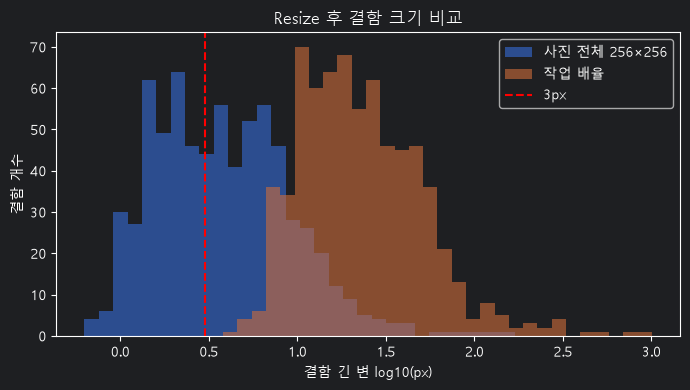

In [35]:
# 작은 결함이 Resize로 사라지는지 확인: '사진 전체를 256으로' vs '작업 배율'
check = lens_instances[lens_instances.official_split != "inference"].copy()
longest = check.image_key.map(lens_images.set_index("image_key").apply(lambda r: max(r.width, r.height), axis=1))
check["side_whole_256"] = check.max_side * 256 / longest
check["side_work_scale"] = check.max_side * check.capture_group.map(LENS_SCALE)
table = pd.DataFrame({"사진 전체 256×256": [(check.side_whole_256 < 3).mean(), check.side_whole_256.median()],
                      "작업 배율 + 256 구역": [(check.side_work_scale < 3).mean(), check.side_work_scale.median()]},
                     index=["3픽셀 미만으로 작아지는 결함 비율", "결함 긴 변 중앙값(px)"])
print(table.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(np.log10(check.side_whole_256.clip(lower=0.1)), bins=30, alpha=0.6, label="사진 전체 256×256")
ax.hist(np.log10(check.side_work_scale.clip(lower=0.1)), bins=30, alpha=0.6, label="작업 배율")
ax.axvline(np.log10(3), color="red", ls="--", label="3px")
ax.set(title="Resize 후 결함 크기 비교", xlabel="결함 긴 변 log10(px)", ylabel="결함 개수")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "preprocess_resize_check.png", dpi=130)
plt.show()

## 구역(patch) 단위 정상/불량 정답 — 정상 사진이 없을 때의 해결 방법
Lens에는 공식 정상 **사진**이 없습니다. 하지만 결함 사진 안에서 **정답 polygon이 하나도 없는 구역**은 라벨러가 "결함 없음"으로 판단한 실제 정상 영역입니다. 그래서 이렇게 정답을 만듭니다.

| 구역 정답 | 조건 |
|---|---|
| **불량 = 1** | 256×256 구역 안 결함 픽셀이 4개 이상 |
| **정상 = 0** | 구역 안 결함 픽셀이 0개 |
| 제외 | 1~3개(결함 가장자리가 살짝 걸친 애매한 구역) |

- 구역 위치는 **사진 크기만으로** 정해지는 격자입니다(정답을 보고 고르지 않음).
- 불량 사진의 모든 구역을 불량으로 붙이지 않습니다.
- 렌즈 면이 20% 미만인 구역은 검사하지 않습니다.
- **train:** 불량 구역 전부 + 결함 중심을 조금 옮긴 구역(결함당 1개, 학습 샘플링 전용) + 정상 구역(불량의 2배를 무작위 추출)
- **validation·test:** 격자 구역 **전부**를 실제 비율 그대로 씁니다(정상이 훨씬 많음).

**사진 판정으로 합치는 방법:** 사진 점수 = 그 사진의 모든 구역 점수 중 **최댓값**입니다. 한 구역이라도 불량 점수가 높으면 그 사진은 불량 쪽입니다.

**한계:** 이것은 "결함 사진 안의 정상 영역"입니다. 결함이 전혀 없는 렌즈 사진에서의 오검출률은 진짜 정상 사진이 있어야 정확히 잴 수 있습니다. 02 노트북의 '팀 라벨 정상 사진' 셀이 그 부분을 채우는 방법입니다.

In [36]:
# 사진 크기만으로 정해지는 격자 구역과 구역 정답(정상 0 / 불량 1 / 제외 -1)을 만듭니다.
def grid_starts(length, patch=PATCH, stride=STRIDE):
    if length <= patch:
        return [0]
    starts = list(range(0, length - patch + 1, stride))
    if starts[-1] != length - patch:
        starts.append(length - patch)
    return starts

def pad_to(array, patch=PATCH):
    pad_h, pad_w = max(0, patch - array.shape[0]), max(0, patch - array.shape[1])
    if pad_h or pad_w:
        array = np.pad(array, ((0, pad_h), (0, pad_w)) + ((0, 0),) * (array.ndim - 2))
    return array

def grid_positions(image_shape, valid):
    # 렌즈 면이 VALID_MIN 이상인 격자 구역만 검사합니다. (사진 픽셀만 사용)
    height, width = max(image_shape[0], PATCH), max(image_shape[1], PATCH)
    valid = pad_to(valid)
    return [(y, x) for y in grid_starts(height) for x in grid_starts(width) if valid[y:y + PATCH, x:x + PATCH].mean() >= VALID_MIN]

def patch_label(mask_patch):
    n = int(mask_patch.sum())
    return 1 if n >= MIN_DEFECT_PX else (0 if n == 0 else -1)

rows = []
sampler = np.random.default_rng(SEED)
for key, work in lens_work.items():
    mask = pad_to(work["mask"])
    for y, x in grid_positions(work["image"].shape, work["valid"]):
        rows.append({"image_key": key, "split": work["split"], "y": y, "x": x, "kind": "grid", "label": patch_label(mask[y:y + PATCH, x:x + PATCH])})
    if work["split"] == "train":  # 결함 중심을 조금 옮긴 구역(학습 샘플링 전용)
        height, width = mask.shape
        for inst in work["instances"]:
            cy, cx = (inst["y0"] + inst["y1"]) / 2, (inst["x0"] + inst["x1"]) / 2
            y = int(np.clip(cy - PATCH / 2 + sampler.integers(-PATCH // 4, PATCH // 4 + 1), 0, height - PATCH))
            x = int(np.clip(cx - PATCH / 2 + sampler.integers(-PATCH // 4, PATCH // 4 + 1), 0, width - PATCH))
            rows.append({"image_key": key, "split": "train", "y": y, "x": x, "kind": "defect_centered", "label": patch_label(mask[y:y + PATCH, x:x + PATCH])})
patch_table = pd.DataFrame(rows)
train_pos = patch_table[(patch_table.split == "train") & (patch_table.label == 1)]
train_neg = patch_table[(patch_table.split == "train") & (patch_table.label == 0) & (patch_table.kind == "grid")]
train_neg = train_neg.sample(n=min(len(train_neg), int(NEG_PER_POS * len(train_pos))), random_state=SEED)
patch_table["use"] = patch_table.split.isin(["validation", "test"]) & (patch_table.label >= 0) & (patch_table.kind == "grid")
patch_table.loc[train_pos.index.union(train_neg.index), "use"] = True
patch_table.to_csv(PROCESSED / f"lens_patch_table_{RUN_MODE}.csv", index=False, encoding="utf-8-sig")
PATCH_SIGNATURE = hashlib.sha256(pd.util.hash_pandas_object(patch_table, index=False).values.tobytes()).hexdigest()
summary = pd.crosstab(patch_table[patch_table.use].split, patch_table[patch_table.use].label).rename(columns={0: "정상 구역", 1: "불량 구역"})
print(summary)
print("제외한 애매한 구역:", int((patch_table.label == -1).sum()))

def preprocess(image, method):
    # 전처리 후보: 원본 RGB / CLAHE(밝기 국소 대비) / Median 3×3(노이즈 제거)
    if method == "rgb":
        return image
    if method == "clahe":
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        lab[:, :, 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[:, :, 0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    if method == "median":
        return cv2.medianBlur(image, 3)
    raise ValueError(method)

_patch_cache = {}
def patch_arrays(split, method="rgb"):
    # X: (N, 256, 256, 3) uint8 RGB / y: (N,) 0·1 / rows: 구역 정보
    key = (split, method)
    if key not in _patch_cache:
        if len(_patch_cache) >= 3:
            _patch_cache.pop(next(iter(_patch_cache)))  # 메모리 절약: 오래된 묶음부터 비움
        rows = patch_table[(patch_table.split == split) & patch_table.use].reset_index(drop=True)
        prepared = {k: pad_to(preprocess(lens_work[k]["image"], method)) for k in rows.image_key.unique()}
        X = np.stack([prepared[r.image_key][r.y:r.y + PATCH, r.x:r.x + PATCH] for r in rows.itertuples()]).astype(np.uint8)
        _patch_cache[key] = (X, rows.label.to_numpy(np.float32), rows)
    return _patch_cache[key]

label       정상 구역  불량 구역
split                   
test         2831    579
train        1518    759
validation    665    141
제외한 애매한 구역: 3


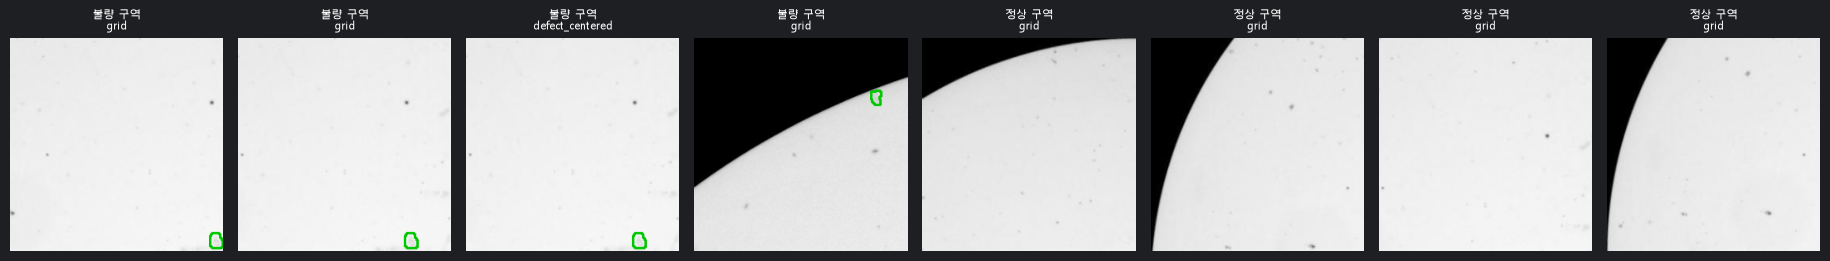

입력 배열: (2277, 256, 256, 3) uint8 값 범위 0 ~ 255 / 정답: (2277,) [0. 1.]


In [37]:
# 구역 예시: 불량 구역(정답 윤곽 초록)과 정상 구역
Xs, ys, rs = patch_arrays("train", "rgb")
picked = list(np.flatnonzero(ys == 1)[:4]) + list(np.flatnonzero(ys == 0)[:4])
fig, axes = plt.subplots(1, len(picked), figsize=(2.3 * len(picked), 3))
for ax, i in zip(axes, picked):
    r = rs.iloc[i]
    patch = Xs[i].copy()
    gt = pad_to(lens_work[r.image_key]["mask"])[r.y:r.y + PATCH, r.x:r.x + PATCH]
    contours, _ = cv2.findContours(cv2.dilate(gt, np.ones((5, 5), np.uint8)), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(patch, contours, -1, (0, 200, 0), 2)
    ax.imshow(patch)
    ax.set_title(("불량 구역" if ys[i] == 1 else "정상 구역") + f"\n{r.kind}", fontsize=8)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "patch_examples.png", dpi=120)
plt.show()
print("입력 배열:", Xs.shape, Xs.dtype, "값 범위", Xs.min(), "~", Xs.max(), "/ 정답:", ys.shape, np.unique(ys))

## PART 04. CNN 모델 직접 구현 (지시서 구조)
```
Input(256,256,3) → Rescaling(1/255) → RandomFlip(학습 때만)
→ Conv2D(32,3×3)+ReLU → MaxPooling2D        (256→128)
→ Conv2D(64,3×3)+ReLU → MaxPooling2D        (128→64)
→ Conv2D(128,3×3)+ReLU
→ GlobalAveragePooling2D                     (64×64×128 → 128)
→ Dense(64, ReLU) → Dense(1, Sigmoid)        (불량 구역 점수 0~1)
```
- 수업에서 배운 Keras `Sequential` 방식입니다.
- `padding="same"`은 가장자리를 0으로 채워 크기를 유지합니다(제로 패딩).
- 사전학습 모델은 쓰지 않습니다.
- **출력:** 정상 구역=0, 불량 구역=1인 Sigmoid 점수 하나입니다. 이 점수는 보정된 실제 불량 확률이 아니라 **모델 점수**입니다.

In [38]:
# [TF] 구역 CNN 학습 함수 (저장 모델 재사용 포함) — 두 노트북 공통
def history_figure(history, name):
    metrics = [m for m in ["loss", "accuracy", "pr_auc"] if m in history]
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 3.4))
    for ax, metric in zip(np.atleast_1d(axes), metrics):
        ax.plot(history[metric], label="train")
        ax.plot(history["val_" + metric], label="validation")
        ax.set(title=f"{name} — {metric}", xlabel="Epoch", ylabel=metric)
        ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}_history.png", dpi=130)
    plt.show()

def save_architecture(model, name):
    lines = []
    model.summary(print_fn=lines.append)
    (MET_DIR / f"{name}_architecture.txt").write_text("\n".join(lines), encoding="utf-8")
    print("\n".join(lines))

def class_weights_from(labels):
    # 학습 정답 개수만 사용: 적은 쪽(불량 구역) 오차를 더 크게 반영
    counts = np.bincount(labels.astype(int), minlength=2)
    return {c: float(len(labels) / (2 * counts[c])) for c in (0, 1)}

def fit_patch_cnn(name, build_fn, method="rgb", use_class_weight=True, learning_rate=1e-3, epochs=None, extra=None):
    epochs = epochs or CNN_EPOCHS
    X, y, _ = patch_arrays("train", method)
    Xv, yv, _ = patch_arrays("validation", method)
    weights = class_weights_from(y) if use_class_weight else None
    tf.keras.utils.set_random_seed(SEED)
    model = build_fn()
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(curve="PR", name="pr_auc"), keras.metrics.Recall(name="recall")])
    signature_value = {"version": "lens-cnn-1.0", "split": SPLIT_SIGNATURE, "patches": PATCH_SIGNATURE, "scale": LENS_SCALE, "patch": PATCH, "stride": STRIDE,
                       "architecture": json.loads(model.to_json()), "method": method, "class_weight": weights, "lr": learning_rate, "epochs": epochs,
                       "batch": BATCH_SIZE, "seed": SEED, "mode": RUN_MODE, "extra": extra}
    signature = hashlib.sha256(json.dumps(signature_value, sort_keys=True, default=str).encode()).hexdigest()
    model_path = MODEL_DIR / f"{name}.keras"
    meta_path = MODEL_DIR / f"{name}.json"
    meta = json.loads(meta_path.read_text(encoding="utf-8")) if meta_path.exists() else {}
    if USE_SAVED_MODELS and model_path.exists() and meta.get("signature") == signature and meta.get("model_sha256") == sha256_file(model_path):
        print(name, "→ 데이터·설정이 같은 저장 모델 재사용")
    else:
        callbacks = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=CNN_PATIENCE, restore_best_weights=True),
                     keras.callbacks.ModelCheckpoint(str(model_path), monitor="val_pr_auc", mode="max", save_best_only=True),
                     keras.callbacks.CSVLogger(str(MET_DIR / f"{name}_history.csv"))]
        started = time.perf_counter()
        history = model.fit(X, y, validation_data=(Xv, yv), class_weight=weights, batch_size=BATCH_SIZE, epochs=epochs, callbacks=callbacks, verbose=2)
        meta = {"signature": signature, "name": name, "task": "lens_patch_binary(0=정상 구역,1=불량 구역)", "method": method, "class_weight": weights,
                "learning_rate": learning_rate, "parameters": int(model.count_params()), "training_seconds": time.perf_counter() - started,
                "epochs_completed": len(history.history["loss"]), "history": {k: [float(v) for v in vals] for k, vals in history.history.items()},
                "model_sha256": sha256_file(model_path), "model_bytes": model_path.stat().st_size, "checkpoint_monitor": "val_pr_auc",
                "train_patches": int(len(y)), "train_defect_patches": int(y.sum()), "extra": extra, "score_is_calibrated_probability": False}
        save_architecture(model, name)
        history_figure(meta["history"], name)
        save_json(meta_path, meta)
    model = keras.models.load_model(model_path, compile=False)  # 저장 파일로만 평가·추론
    def predict_fn(batch):
        out = []
        for start in range(0, len(batch), 64):
            out.append(model(batch[start:start + 64].astype(np.float32), training=False).numpy().reshape(-1))
        return np.concatenate(out) if out else np.zeros(0, np.float32)
    return {"name": name, "model": model, "meta": meta, "meta_path": meta_path, "model_path": model_path, "predict": predict_fn, "method": method}

In [39]:
# [TF] Baseline CNN 구조 (지시서 그대로)
def build_baseline_cnn():
    model = keras.Sequential(name="lens_cnn_baseline")
    model.add(layers.Input((IMAGE_SIZE, IMAGE_SIZE, 3), name="image"))
    model.add(layers.Rescaling(1.0 / 255.0, name="normalize"))  # 0~255 → 0~1
    model.add(layers.RandomFlip("horizontal_and_vertical", seed=SEED, name="train_flip"))  # 학습 때만 작동
    model.add(layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"))
    model.add(layers.MaxPooling2D(name="pool1"))
    model.add(layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"))
    model.add(layers.MaxPooling2D(name="pool2"))
    model.add(layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3"))
    model.add(layers.GlobalAveragePooling2D(name="gap"))
    model.add(layers.Dense(64, activation="relu", name="dense"))
    model.add(layers.Dense(1, activation="sigmoid", name="defect_score"))
    return model

preview = build_baseline_cnn()
preview.summary()
print("파라미터 수:", preview.count_params())

Model: "lens_cnn_baseline"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 normalize (Rescaling)       (None, 256, 256, 3)       0         
                                                                 
 train_flip (RandomFlip)     (None, 256, 256, 3)       0         
                                                                 
 conv1 (Conv2D)              (None, 256, 256, 32)      896       
                                                                 
 pool1 (MaxPooling2D)        (None, 128, 128, 32)      0         
                                                                 
 conv2 (Conv2D)              (None, 128, 128, 64)      18496     
                                                                 
 pool2 (MaxPooling2D)        (None, 64, 64, 64)        0         
                                                                 
 conv3 (Conv2D)              (None, 64, 64, 128) 

## PART 05. CNN 학습
- **옵티마이저·손실:** Adam(학습률 0.001), Binary Crossentropy
- **배치·epoch:** 배치 16, 최대 20 epoch
- **멈춤·저장:** `EarlyStopping`과 `ModelCheckpoint`는 검증 **PR-AUC**를 감시합니다. 정상 구역이 훨씬 많아 Accuracy는 쉽게 높아지기 때문입니다.
- **Baseline 설정:** 클래스 가중치를 쓰지 않습니다. 학습 구역은 불량 1 : 정상 2로 뽑았습니다.
- **저장 위치:** full 모드에서는 `models/lens_cnn_baseline.keras`로 저장합니다.

Epoch 1/20
143/143 - 54s - loss: 0.6417 - accuracy: 0.6702 - pr_auc: 0.3857 - recall: 0.0764 - val_loss: 0.5437 - val_accuracy: 0.7667 - val_pr_auc: 0.1903 - val_recall: 0.1277 - 54s/epoch - 379ms/step
Epoch 2/20
143/143 - 49s - loss: 0.6071 - accuracy: 0.6838 - pr_auc: 0.4581 - recall: 0.2082 - val_loss: 0.4817 - val_accuracy: 0.7345 - val_pr_auc: 0.2476 - val_recall: 0.2979 - 49s/epoch - 342ms/step
Epoch 3/20
143/143 - 46s - loss: 0.5610 - accuracy: 0.6847 - pr_auc: 0.4915 - recall: 0.2978 - val_loss: 0.4673 - val_accuracy: 0.7308 - val_pr_auc: 0.2469 - val_recall: 0.3617 - 46s/epoch - 319ms/step
Epoch 4/20
143/143 - 45s - loss: 0.5561 - accuracy: 0.6930 - pr_auc: 0.4982 - recall: 0.3347 - val_loss: 0.4628 - val_accuracy: 0.8002 - val_pr_auc: 0.2880 - val_recall: 0.1844 - 45s/epoch - 316ms/step
Epoch 5/20
143/143 - 45s - loss: 0.5535 - accuracy: 0.6917 - pr_auc: 0.5069 - recall: 0.3439 - val_loss: 0.4600 - val_accuracy: 0.7407 - val_pr_auc: 0.2880 - val_recall: 0.3972 - 45s/epoch - 3

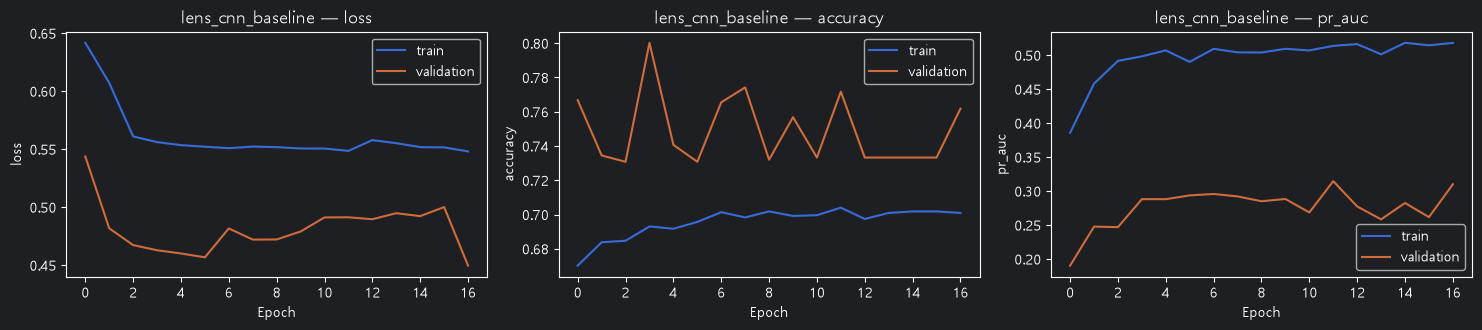

{'parameters': 101569, 'epochs_completed': 17, 'training_seconds': 782.8305645000073, 'train_patches': 2277, 'train_defect_patches': 759}


In [40]:
# Baseline 학습 (또는 같은 조건의 저장 모델 재사용)
baseline_run = fit_patch_cnn("lens_cnn_baseline", build_baseline_cnn, method="rgb", use_class_weight=False, learning_rate=LEARNING_RATE)
print({k: baseline_run["meta"].get(k) for k in ["parameters", "epochs_completed", "training_seconds", "train_patches", "train_defect_patches"]})

In [41]:
# 평가 도구: 구역 지표·검증 기반 경계·사진 단위 합치기 (TensorFlow 불필요)
def binary_metrics(y, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": float(threshold), "accuracy": float(accuracy_score(y, predicted)), "precision": float(precision_score(y, predicted, zero_division=0)),
            "recall": float(recall_score(y, predicted, zero_division=0)), "f1": float(f1_score(y, predicted, zero_division=0)),
            "roc_auc": float(roc_auc_score(y, scores)) if both else None, "average_precision": float(average_precision_score(y, scores)) if both else None,
            "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn), "false_positive_rate": float(fp / (fp + tn)) if fp + tn else None,
            "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]]}

def threshold_for_recall(labels, scores, target):
    # 검증에서 불량 Recall이 target 이상인 경계 중 Precision이 가장 높은 값(같으면 높은 경계)
    candidates = []
    for threshold in np.unique(scores):
        predicted = scores >= threshold
        if recall_score(labels, predicted, zero_division=0) >= target:
            candidates.append((precision_score(labels, predicted, zero_division=0), float(threshold)))
    return max(candidates)[1] if candidates else float(scores.min())

def decide(score, ok_upper, ng):
    # 사진 점수 → OK / REVIEW / NG
    return "NG" if score >= ng else ("OK" if score < ok_upper else "REVIEW")

def image_scores(rows, scores):
    # 사진 점수 = 그 사진 구역 점수의 최댓값
    frame = rows[["image_key"]].copy()
    frame["score"] = scores
    return frame.groupby("image_key").score.max()

def image_level_summary(img_scores, ok_upper, ng):
    # 정답이 있는 test 사진은 모두 결함 사진(y=1)입니다 → 불량 Recall만 계산 가능, 정상 오검출은 측정 불가
    decisions = img_scores.map(lambda s: decide(s, ok_upper, ng))
    n = len(decisions)
    return {"images": n, "defect_images": n, "normal_images": 0, "NG": int((decisions == "NG").sum()), "REVIEW": int((decisions == "REVIEW").sum()),
            "OK": int((decisions == "OK").sum()), "auto_ng_recall": float((decisions == "NG").mean()) if n else None,
            "not_ok_recall_including_review": float((decisions != "OK").mean()) if n else None,
            "defect_passed_as_ok": int((decisions == "OK").sum()), "normal_false_positive_rate": None,
            "normal_false_positive_reason": "test에 공식 정상 사진 0장 — 측정 불가", "decisions": decisions}

def plot_evaluation(y, scores, threshold, title, path):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    matrix = confusion_matrix(y, (scores >= threshold).astype(int), labels=[0, 1])
    axes[0].imshow(matrix, cmap="Blues")
    for (r, c), v in np.ndenumerate(matrix):
        axes[0].text(c, r, str(v), ha="center", va="center")
    axes[0].set_xticks([0, 1], ["정상 구역", "불량 구역"])
    axes[0].set_yticks([0, 1], ["정상 구역", "불량 구역"])
    axes[0].set_xlabel("예측")
    axes[0].set_ylabel("정답")
    axes[0].set_title(f"혼동행렬 (경계 {threshold:.3f})")
    fpr, tpr, _ = roc_curve(y, scores)
    axes[1].plot(fpr, tpr)
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    axes[1].set(title=f"ROC (AUC {roc_auc_score(y, scores):.3f})", xlabel="정상 오검출률(FPR)", ylabel="불량 Recall")
    precision, recall, _ = precision_recall_curve(y, scores)
    axes[2].plot(recall, precision)
    axes[2].set(title=f"Precision-Recall (AP {average_precision_score(y, scores):.3f})", xlabel="Recall", ylabel="Precision")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()

def plot_patch_mistakes(rows, scores, threshold, method, title, path, limit=8):
    # 놓친 불량 구역(FN)을 먼저, 그다음 정상 오검출(FP)을 정답 윤곽(초록)과 함께 보여 줍니다.
    y = rows.label.to_numpy()
    fn = np.flatnonzero((y == 1) & (scores < threshold))
    fp = np.flatnonzero((y == 0) & (scores >= threshold))
    picked = list(fn[np.argsort(scores[fn])][: limit // 2 + max(0, limit // 2 - len(fp))]) + list(fp[np.argsort(-scores[fp])][: limit // 2])
    if not picked:
        return
    fig, axes = plt.subplots(1, len(picked), figsize=(2.4 * len(picked), 3.2), squeeze=False)
    for ax, i in zip(axes[0], picked):
        r = rows.iloc[i]
        patch = pad_to(preprocess(lens_work[r.image_key]["image"], method))[r.y:r.y + PATCH, r.x:r.x + PATCH].copy()
        gt = pad_to(lens_work[r.image_key]["mask"])[r.y:r.y + PATCH, r.x:r.x + PATCH]
        contours, _ = cv2.findContours(cv2.dilate(gt, np.ones((5, 5), np.uint8)), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(patch, contours, -1, (0, 200, 0), 2)
        ax.imshow(patch)
        ax.set_title(("놓친 불량(FN)" if y[i] == 1 else "정상 오검출(FP)") + f"\n점수 {scores[i]:.3f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.show()

## PART 06. Baseline 성능 평가
1. **경계는 validation으로만 정합니다.**
   - NG 경계: 검증 불량 구역 Recall 95% 이상인 경계 중 Precision이 가장 높은 값
   - OK 경계: Recall 99% 기준(더 낮은 값)
   - 두 경계 사이: REVIEW
2. **test:** 공식 Val에서 누수 사진을 뺀 52장의 모든 구역을 **한 번** 평가합니다.
3. **구역 단위 지표:** Accuracy·Precision·Recall·F1·ROC-AUC·AP·혼동행렬·FP·FN
4. **사진 단위:** test 사진은 모두 결함 사진입니다.
   - 계산할 수 있는 것: **불량 사진 Recall**(자동 NG 비율), **OK로 통과된 불량 사진 수**
   - 계산할 수 없는 것: 정상 사진 오검출률 → `N/A`(정상 사진 0장)

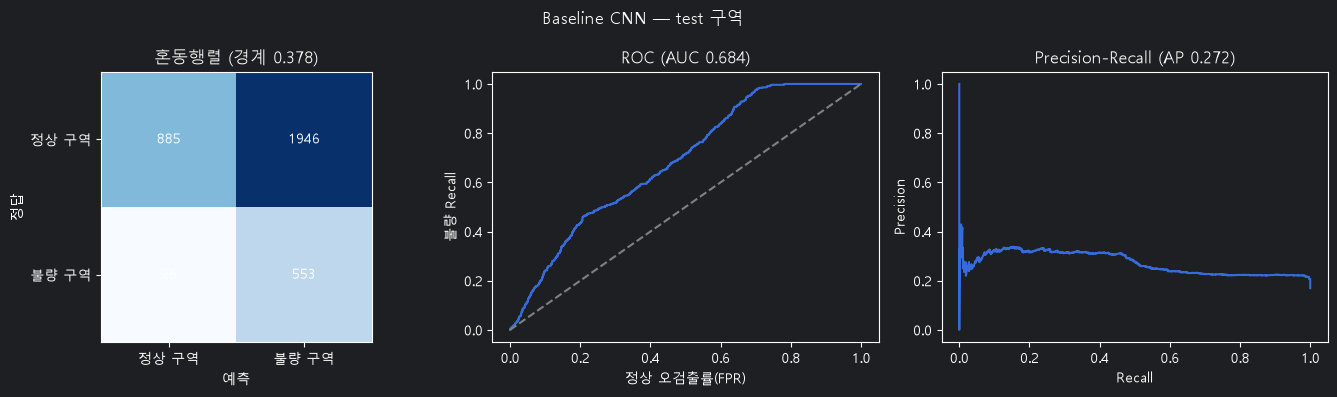

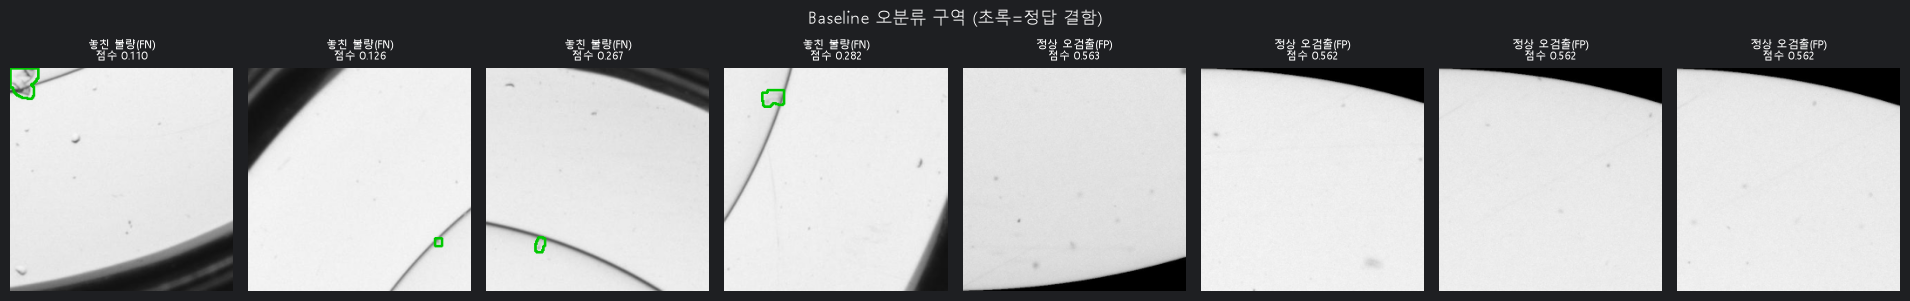

                     validation       test
accuracy                 0.4243     0.4217
precision                0.2295     0.2213
recall                   0.9716     0.9551
f1                       0.3713     0.3593
roc_auc                  0.7060     0.6844
average_precision        0.3147     0.2724
TP                     137.0000   553.0000
FP                     460.0000  1946.0000
TN                     205.0000   885.0000
FN                       4.0000    26.0000
false_positive_rate      0.6917     0.6874
경계 OK< 0.3373 / NG≥ 0.3781
test 사진: {'images': 52, 'NG': 52, 'REVIEW': 0, 'OK': 0, 'auto_ng_recall': 1.0, 'not_ok_recall_including_review': 1.0, 'defect_passed_as_ok': 0}


In [42]:
# 검증으로 경계 결정 → test 평가
Xv, yv, rows_v = patch_arrays("validation", "rgb")
val_scores = baseline_run["predict"](Xv)
NG_T = threshold_for_recall(yv, val_scores, RECALL_TARGET)
OK_T = min(NG_T, threshold_for_recall(yv, val_scores, REVIEW_RECALL))
val_metrics = binary_metrics(yv, val_scores, NG_T)

Xt, yt, rows_t = patch_arrays("test", "rgb")
started = time.perf_counter()
test_scores = baseline_run["predict"](Xt)
elapsed = time.perf_counter() - started
test_metrics = binary_metrics(yt, test_scores, NG_T)
img = image_level_summary(image_scores(rows_t, test_scores), OK_T, NG_T)
plot_evaluation(yt, test_scores, NG_T, "Baseline CNN — test 구역", FIG_DIR / "baseline_evaluation.png")
plot_patch_mistakes(rows_t, test_scores, NG_T, "rgb", "Baseline 오분류 구역 (초록=정답 결함)", FIG_DIR / "baseline_mistakes.png")

baseline_result = {
    "model": "lens_cnn_baseline", "model_path": str(baseline_run["model_path"].relative_to(ROOT)), "mode": RUN_MODE,
    "task_type": "lens_patch_binary (256×256 구역: 0=정상 구역, 1=불량 구역) + 사진 판정=구역 점수 최댓값",
    "thresholds": {"ok_upper": OK_T, "ng": NG_T, "source": "validation only", "recall_target": RECALL_TARGET, "review_recall_target": REVIEW_RECALL},
    "counts": {"train_images": len(split_keys("train")), "validation_images": len(split_keys("validation")), "test_images": len(split_keys("test")),
               "validation_patches": int(len(yv)), "test_patches": int(len(yt)), "test_defect_patches": int(yt.sum())},
    "validation_patch": val_metrics, "test_patch": test_metrics, "test_image": {k: v for k, v in img.items() if k != "decisions"},
    "training_seconds": baseline_run["meta"].get("training_seconds"), "parameters": baseline_run["meta"].get("parameters"),
    "inference_ms_per_patch": 1000 * elapsed / max(1, len(yt)), "inference_ms_per_image": 1000 * elapsed / max(1, len(img["decisions"])),
    "not_available": {"image_level_false_positive_rate": "공식 정상 사진 0장", "image_level_precision": "정상 사진이 없어 의미 없음"}}
save_json(MET_DIR / "lens_baseline_metrics.json", baseline_result)
patch_out = rows_t[["image_key", "y", "x", "label"]].assign(score=test_scores, predicted=(test_scores >= NG_T).astype(int))
patch_out.to_csv(PRED_DIR / "lens_baseline_test_patches.csv", index=False, encoding="utf-8-sig")
img["decisions"].rename("decision").to_frame().assign(score=image_scores(rows_t, test_scores)).to_csv(PRED_DIR / "lens_baseline_test_images.csv", encoding="utf-8-sig")
show = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "TP", "FP", "TN", "FN", "false_positive_rate"]
print(pd.DataFrame({"validation": {k: val_metrics[k] for k in show}, "test": {k: test_metrics[k] for k in show}}).round(4))
print("경계 OK<", round(OK_T, 4), "/ NG≥", round(NG_T, 4))
print("test 사진:", {k: img[k] for k in ["images", "NG", "REVIEW", "OK", "auto_ng_recall", "not_ok_recall_including_review", "defect_passed_as_ok"]})

## PART 07. 결과 저장과 Baseline의 장점·한계
**저장 파일**
- `models/lens_cnn_baseline.keras` + `lens_cnn_baseline.json`(학습 이력·서명)
- `outputs/metrics/lens_baseline_metrics.json`, `lens_cnn_baseline_architecture.txt`, `lens_cnn_baseline_history.csv`
- `outputs/figures/`: 학습 곡선, 혼동행렬·ROC·PR, 오분류 구역, EDA 그림
- `outputs/predictions/`: test 구역별·사진별 점수

**장점**
- 수업에서 배운 Conv·Pooling·Dense만으로 만든 단순한 구조라 이해하기 쉽습니다.
- 파라미터가 적어 CPU에서도 학습할 수 있습니다.
- 정상 사진이 없어도, 실제 마스크로 만든 구역 정답으로 정상/불량 이진 학습을 할 수 있습니다.

**한계**
- `GlobalAveragePooling`은 64×64 특징 지도를 평균 냅니다. 그래서 몇 픽셀짜리 작은 결함의 신호가 묽어질 수 있습니다. 02에서 GlobalMaxPooling·BatchNorm·Dropout으로 개선을 시도합니다.
- 사진 단위 정상 오검출률은 정상 사진이 없어 잴 수 없습니다.
- 정답 polygon 밖에도 표시되지 않은 어두운 점이 많습니다. 그래서 '정상 구역' 안에 실제 미세 결함이 섞였을 수 있습니다.
- test는 사진 52장(공개 데이터의 공식 Val)입니다. 독립된 외부 검증이 아닙니다.